---
title: "Time-Dependent Perturbation Theory — Level 2"
short_title: "10 Time-Dependent Perturbations"
numbering:
  heading_2: true
  equation: true
---

# Time-Dependent Perturbation Theory

:::{seealso} Math for this topic
- [M4: Linear ODEs, Fourier series and transforms](../../level2-book/math/04-linear-odes-fourier.ipynb)
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [M2: Coordinates, integrals and the delta function](../../level2-book/math/02-coordinates-integrals-delta.ipynb)
- [E-M3: Waves and Fourier transforms](../../level2-em-book/math/03-waves-fourier-transforms.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Griffiths QM, ch. 9** | **Two-level systems, Fermi's golden rule, emission and absorption** |
| 3 | Sakurai, ch. 5 | Interaction picture, Dyson series, the adiabatic theorem, Berry's phase |

The new skill at this level: computing transition probabilities between stationary states when the Hamiltonian changes in time

Math for this topic: mechanics M4 (second-order ODEs, Fourier), mechanics M6 (matrices), mechanics M2 (the delta function) and E&M E-M3 (Fourier transforms).
:::

Workbook example ladder: Rabi oscillations → the spontaneous emission rate → Berry's phase from adiabatic transport. Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Scattering](11-scattering.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Transitions**

   To first order, $c_b(t) = -\dfrac{i}{\hbar}\displaystyle\int_0^tH'_{ba}(t')\,e^{i\omega_0t'}\,dt'$.

   (a) Find $P_{a\to b}$ for a constant $H'$ switched on at $t = 0$.

   (b) Find $P_{a\to b}$ for a sudden kick $H' = V\,\delta(t)$.

2. **A Sinusoidal Perturbation**

   For driving near resonance, how does the first-order transition probability depend on the detuning? How does the width of the resonance change with the duration $t$?

3. **Rabi Oscillations**

   $P(t) = \dfrac{\Omega^2}{\Omega^2 + \delta^2}\sin^2\left(\tfrac12\sqrt{\Omega^2 + \delta^2}\,t\right)$.

   (a) On resonance, how long is a $\pi$ pulse, and what does it do?

   (b) With detuning $\delta = \Omega$, what is the largest transition probability?

4. **Fermi's Golden Rule**

   (a) State the golden rule.

   (b) What happens to the rate if the density of final states doubles?

   (c) Why does a constant transition rate give exponential decay?

5. **Emission and Absorption of Light**

   (a) Which of these are allowed electric-dipole transitions in hydrogen: $4f\to3d$, $4f\to2s$, $3s\to2p$, $3d\to2s$?

   (b) Why is the $2s$ state long-lived?

   (c) How does the spontaneous emission rate scale with frequency?

:::{dropdown} Answers
1. (a) $P = \dfrac{4|H'_{ba}|^2}{\hbar^2\omega_0^2}\sin^2\left(\dfrac{\omega_0t}{2}\right)$.

   (b) $P = |V_{ba}|^2/\hbar^2$.

2. $P \propto \dfrac{\sin^2\left[(\omega_0 - \omega)t/2\right]}{(\omega_0 - \omega)^2}$. The resonance width shrinks as about $2\pi/t$.

3. (a) $t = \pi/\Omega$. It moves the system completely from $a$ to $b$ (full inversion).

   (b) $\dfrac{\Omega^2}{\Omega^2 + \Omega^2} = \tfrac12$.

4. (a) Rate $= \dfrac{2\pi}{\hbar}|V_{fi}|^2\rho(E_f)$.

   (b) It doubles.

   (c) Each atom has the same probability per unit time of decaying, so $dN/dt = -\Gamma N$.

5. (a) $4f\to3d$ and $3s\to2p$ are allowed ($\Delta\ell = \pm1$). $4f\to2s$ ($\Delta\ell = 3$) and $3d\to2s$ ($\Delta\ell = 2$) are forbidden.

   (b) Its only lower state is $1s$, and $\Delta\ell = 0$ is forbidden for a dipole transition. It decays mainly by two-photon emission.

   (c) As $\omega^3|\langle f|\vec{r}|i\rangle|^2$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Transitions

Stationary states never change. A time-dependent perturbation $\hat H'(t)$ (a light wave passing an atom, a pulse in an NMR coil) makes the system jump between them, and the question becomes: starting in state $a$, what is the probability of finding it in state $b$ later?

Take two unperturbed states, $\hat H^0\psi_a = E_a\psi_a$ and $\hat H^0\psi_b = E_b\psi_b$, with $\omega_0 = (E_b - E_a)/\hbar > 0$. Write

$$
\Psi(t) = c_a(t)\psi_ae^{-iE_at/\hbar} + c_b(t)\psi_be^{-iE_bt/\hbar} .
$$

The stationary phases are pulled out, so $c_a$ and $c_b$ change only because of $\hat H'$. Substituting into the Schrödinger equation (assuming, as is usual, $H'_{aa} = H'_{bb} = 0$) gives

$$
\dot c_a = -\frac i\hbar H'_{ab}e^{-i\omega_0t}c_b,\qquad
\dot c_b = -\frac i\hbar H'_{ba}e^{i\omega_0t}c_a ,
$$ (eq-two-level-tdpt)

with $H'_{ab} = \langle\psi_a|\hat H'(t)|\psi_b\rangle$. These are exact. **First-order perturbation theory** puts $c_a\approx1$ on the right:

$$
c_b(t)\approx-\frac i\hbar\int_0^tH'_{ba}(t')e^{i\omega_0t'}\,dt' .
$$ (eq-first-order-cb)

The transition amplitude is the Fourier component of the perturbation at the transition frequency $\omega_0$ (E-M3).

## A Sinusoidal Perturbation

For $\hat H' = V(\vec r)\cos\omega t$ with $\omega$ near $\omega_0$, keep the term in {eq}`eq-first-order-cb` that oscillates slowly (dropping $e^{i(\omega_0 + \omega)t}$ is the **rotating-wave approximation**):

$$
P_{a\to b}(t) = |c_b|^2\approx\frac{|V_{ba}|^2}{\hbar^2}\frac{\sin^2\left[(\omega_0 - \omega)t/2\right]}{(\omega_0 - \omega)^2} .
$$ (eq-sinusoidal-transition)

Two features: the response is peaked at resonance with width $\sim2\pi/t$ (a longer exposure picks out the frequency more sharply), and at exact resonance $P$ grows like $t^2$, which cannot last since probabilities stay below 1.

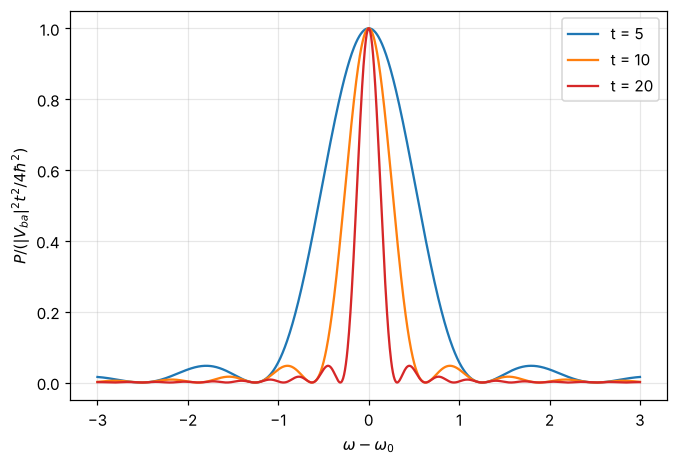

In [2]:
#| label: fig-transition-lineshape
#| caption: "First-order transition probability (per |V_ba|²t²/4ħ², so the peak is 1) versus detuning ω − ω₀ for exposure times t = 5, 10 and 20 (arbitrary units). The central peak narrows like 1/t while its height grows like t², so the area grows like t: the seed of the golden rule's constant rate."
dw = np.linspace(-3, 3, 1200)
fig, ax = plt.subplots()
for t, col in [(5, "tab:blue"), (10, "tab:orange"), (20, "tab:red")]:
    P = np.sinc(dw * t / (2 * np.pi))**2          # sin^2(x)/x^2 with x = dw t/2
    ax.plot(dw, P, color=col, label=f"t = {t}")
ax.set_xlabel("$\\omega - \\omega_0$"); ax.set_ylabel("$P / (|V_{ba}|^2t^2/4\\hbar^2)$"); ax.legend(); plt.show()

## Rabi Oscillations

The exact equations {eq}`eq-two-level-tdpt` with the rotating-wave approximation can be solved without assuming $P$ is small. Starting in $a$,

$$
P_{a\to b}(t) = \frac{\Omega^2}{\Omega^2 + \delta^2}\sin^2\!\left(\frac{\sqrt{\Omega^2 + \delta^2}}{2}t\right),\qquad
\Omega = \frac{|V_{ab}|}{\hbar},\ \ \delta = \omega - \omega_0 .
$$ (eq-rabi)

At resonance the system swings completely from $a$ to $b$ and back at the **Rabi frequency** $\Omega$. A pulse lasting $\pi/\Omega$ (a "π pulse") flips the state exactly; this is how NMR flips nuclear spins and how quantum computers apply a NOT gate. For small $t$, {eq}`eq-rabi` reduces to {eq}`eq-sinusoidal-transition`.

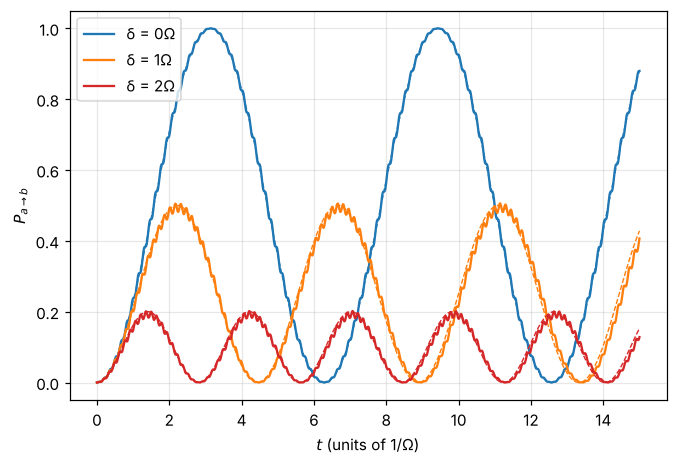

In [3]:
#| label: fig-rabi
#| caption: "Rabi oscillations in a driven two-level system (ω₀ = 20, Ω = 1). Solid lines integrate the full equations numerically (no rotating-wave approximation); dashed lines are the rotating-wave formula above. On resonance the population transfers completely; detuned by δ = Ω or 2Ω, the oscillation is faster and incomplete. The small wiggles in the solid curves are the counter-rotating terms the formula drops."
w0, Om = 20.0, 1.0
def rhs(t, c, w):
    ca, cb = c[0] + 1j * c[1], c[2] + 1j * c[3]
    Hab = Om * np.cos(w * t)           # V_ab cos(wt)/hbar with V_ab = hbar*Om (so on resonance the Rabi frequency is Om)
    dca = -1j * Hab * np.exp(-1j * w0 * t) * cb
    dcb = -1j * Hab * np.exp(1j * w0 * t) * ca
    return [dca.real, dca.imag, dcb.real, dcb.imag]
ts = np.linspace(0, 15, 1500)
fig, ax = plt.subplots()
for d, col in [(0, "tab:blue"), (1, "tab:orange"), (2, "tab:red")]:
    sol = solve_ivp(rhs, (0, 15), [1, 0, 0, 0], t_eval=ts, args=(w0 + d,), rtol=1e-9, atol=1e-11, max_step=0.01)
    ax.plot(ts, sol.y[2]**2 + sol.y[3]**2, color=col, label=f"δ = {d}Ω")
    W = np.sqrt(Om**2 + d**2)
    ax.plot(ts, Om**2 / W**2 * np.sin(W * ts / 2)**2, "--", color=col, lw=0.9)
ax.set_xlabel("$t$ (units of 1/Ω)"); ax.set_ylabel("$P_{a\\to b}$"); ax.legend(); plt.show()

Here $V_{ab}$ is the amplitude multiplying $\cos\omega t$. The rotating-wave approximation keeps only half of the cosine, $\tfrac12e^{-i\omega t}$, which is where the $/2$ inside the sine comes from.

## Fermi's Golden Rule

If the final state is not one level but a continuum (a free electron in photoionization, a photon in any direction and frequency), sum {eq}`eq-sinusoidal-transition` over final states with density $\rho(E)$ per unit energy. For large $t$, $\sin^2(xt/2)/x^2\to\frac{\pi t}{2}\delta(x)$, the probability becomes proportional to $t$, and the **rate** is constant:

$$
R_{a\to f} = \frac{2\pi}{\hbar}|V_{fa}|^2\rho(E_f) .
$$ (eq-golden-rule)

(The factor depends on whether $V$ is written with $\cos\omega t$ or $e^{-i\omega t}$; this is the form for $\hat H' = Ve^{-i\omega t}$.) Most decay rates in physics, from atoms to nuclei to particle physics, are computed this way.

## Emission and Absorption of Light

An atom in a light wave feels $\hat H' = -q\vec E\cdot\hat{\vec r} = -\hat{\vec p}_e\cdot\vec E_0\cos\omega t$ (the **electric dipole approximation**: the wavelength is much longer than the atom, so $\vec E$ is uniform across it). Transitions need a nonzero dipole matrix element $\langle b|q\hat{\vec r}|a\rangle$, which gives the **selection rules**

$$
\Delta\ell = \pm1,\qquad\Delta m = 0, \pm1 .
$$ (eq-selection-rules)

Parity explains $\Delta\ell$ odd: $\vec r$ is odd, so $a$ and $b$ must have opposite parity, $(-1)^\ell$. Angular-momentum addition (the photon carries one unit) restricts it to $\pm1$.

**Spontaneous emission.** An excited atom decays even in the dark. Einstein deduced the rate from thermal equilibrium with blackbody radiation (thermo topic 7): absorption, stimulated emission and spontaneous emission must balance the Planck spectrum, which fixes

$$
A = \frac{\omega_0^3|\vec p_{ba}|^2}{3\pi\epsilon_0\hbar c^3} .
$$ (eq-einstein-A)

The $\omega^3$ means high-frequency transitions decay fast: optical transitions in nanoseconds, radio transitions (like hydrogen's 21 cm line) in millions of years.

In [4]:
# Lifetime of hydrogen 2p -> 1s: |<100| r |21m>|^2 is the same for each m; take m = 0, where only z contributes
r, th = sp.symbols("r theta", positive=True)
a0_ = sp.symbols("a", positive=True)
R10 = 2 / a0_**sp.Rational(3, 2) * sp.exp(-r / a0_)
R21 = 1 / sp.sqrt(24) / a0_**sp.Rational(3, 2) * (r / a0_) * sp.exp(-r / (2 * a0_))
Y00 = 1 / sp.sqrt(4 * sp.pi); Y10 = sp.sqrt(3 / (4 * sp.pi)) * sp.cos(th)
zme = sp.simplify(sp.integrate(sp.integrate(R10 * Y00 * r * sp.cos(th) * R21 * Y10 * r**2 * sp.sin(th), (th, 0, sp.pi)) * 2 * sp.pi, (r, 0, sp.oo)))
display(Math(r"\langle 100|z|210\rangle = " + sp.latex(zme) + rf" \approx {float(zme / a0_):.4f}\,a"))
e, eps0, c = 1.602177e-19, 8.854188e-12, 2.997925e8
w = (10.2 * e) / hbar
p2 = (e * float(zme / a0_) * a0)**2
A = w**3 * p2 / (3 * np.pi * eps0 * hbar * c**3)
display(Math(rf"A = {A:.3e}\ \text{{s}}^{{-1}},\qquad \tau = 1/A = {1e9 / A:.2f}\ \text{{ns}}\quad(\text{{measured }} 1.60\ \text{{ns}})"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Looking Ahead to Level 3

Sakurai organizes all of this in the **interaction picture**, where the state evolves only under $\hat H'$, and writes the full evolution as the **Dyson series**, of which {eq}`eq-first-order-cb` is the first term. The opposite limit, a Hamiltonian that changes *slowly*, gives the **adiabatic theorem**: a system starting in the $n$th eigenstate stays in the $n$th eigenstate of the instantaneous Hamiltonian. Taken around a closed loop in parameter space, it returns with an extra geometric phase, **Berry's phase**, which depends only on the loop's shape. A spin-½ whose field direction is slowly carried around a cone picks up a phase equal to $-\tfrac12$ the solid angle of the cone.

## Exercises

### Exercises

1. A perturbation $\hat H' = V\,e^{-t^2/\tau^2}$ (a Gaussian pulse) acts on a two-level system. Find $P_{a\to b}$ to first order and show it is largest for $\tau\sim1/\omega_0$. What happens for very slow pulses?
2. Show that {eq}`eq-rabi` reduces to {eq}`eq-sinusoidal-transition` when $\Omega t\ll1$.
3. For hydrogen, which of these are allowed electric-dipole transitions: $3s\to1s$, $3p\to1s$, $3d\to2p$, $3d\to1s$, $2s\to1s$?
4. Use {eq}`eq-einstein-A` and the matrix element above to explain why the $3p\to1s$ rate is lower than $2p\to1s$ despite the larger frequency, given $|\langle100|z|310\rangle|\approx0.30a$.
5. How long is a π pulse for a proton spin in NMR if the oscillating field gives $\Omega = 2\pi\times25$ kHz?

:::{dropdown} Hints
1. $c_b\propto\int e^{-t^2/\tau^2}e^{i\omega_0t}dt$, a Gaussian Fourier transform.
2. For small arguments, $\sin^2(\sqrt{\Omega^2 + \delta^2}\,t/2)\approx\sin^2(\delta t/2)$ when $\delta\gg\Omega$; or expand to $t^2$ at resonance.
3. $\Delta\ell = \pm1$.
4. Compare $\omega^3|p|^2$ for both.
5. $t = \pi/\Omega$.
:::

:::{dropdown} Answers
1. $P = \pi|V_{ba}|^2\tau^2e^{-\omega_0^2\tau^2/2}/\hbar^2$, maximized at $\tau = \sqrt2/\omega_0$. Very slow pulses ($\omega_0\tau\gg1$) cause almost no transitions: the adiabatic limit.
2. At resonance both give $P\approx\Omega^2t^2/4$ for small $t$; off resonance with $\delta\gg\Omega$, both give $(\Omega/\delta)^2\sin^2(\delta t/2)$.
3. Allowed: $3p\to1s$, $3d\to2p$. Forbidden: $3s\to1s$, $3d\to1s$, $2s\to1s$ (the $2s$ state is metastable, lasting about 0.1 s via two-photon decay).
4. $\omega^3$ grows by $(12.09/10.2)^3 = 1.67$ but $|p|^2$ drops by $(0.30/0.745)^2 = 0.16$; net rate about 0.27 of $2p\to1s$, before accounting for the branch to $2s$.
5. $t = \pi/(2\pi\times25\text{ kHz}) = 20$ μs.
:::

## Summary

- Expand in stationary states with time-dependent coefficients; first order gives $c_b = -\tfrac i\hbar\int H'_{ba}e^{i\omega_0t}dt$, the perturbation's Fourier component at $\omega_0$.
- Sinusoidal driving: resonance with width $\sim1/t$; exactly (in the rotating-wave approximation), Rabi oscillations at $\sqrt{\Omega^2 + \delta^2}$.
- Fermi's golden rule: transitions into a continuum happen at a constant rate $\tfrac{2\pi}\hbar|V|^2\rho$.
- Dipole selection rules $\Delta\ell = \pm1$, $\Delta m = 0, \pm1$; spontaneous emission rate $\propto\omega^3|p|^2$, giving 1.6 ns for hydrogen $2p$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.